In [1]:
##############################################################################################################################################################################################################################################################
### Map the MADM cells onto the Xenium data

In [2]:
import sys
print(sys.executable) # Run the program in the Xenium environment you created

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/bin/python


In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import h5py
import anndata as ad
import matplotlib.pyplot as plt
import warnings
import os
import squidpy as sq
import spatialdata as sd
import spatialdata_io as sio
import spatialdata_plot
from scipy import sparse
from pathlib import Path
import seaborn as sns
CONFIG_DIR = Path("Notebooks")
sys.path.append(str(CONFIG_DIR))
import importlib
import xenium_config

importlib.reload(xenium_config)

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from

<module 'xenium_config' from '/nfs/scistore23/sweengrp/sgobeil/Xenium Data Analysis/Xenium-MADM/Notebooks/xenium_config.py'>

In [4]:
sc.settings.verbosity = 3

In [5]:
### Load the data
adata_madm = sc.read_h5ad("Processed/MADM_preprocessed.h5ad")

adata_madm_neurons = sc.read_h5ad("Processed/MADM_neurons.h5ad")

adata_combined = sc.read_h5ad("Processed/Xenium_allcell_reference.h5ad")

adata_neurons_SCNeuron_genes = sc.read_h5ad("Processed/Xen-MADM_neurons_SCgenes_reclustered.h5ad")

In [6]:
#######################################################################################################################
### Use the MADM cells as a query

In [7]:
### ALL CELLS 
### Scale the MADM cells using the same std as in the Xenium cells so that the MADM cells enter on the same numerical scale
# Same genes, in exactly the same order as the reference
adata_madm_all_query = adata_madm[:,adata_combined.var_names].copy()

X_query = adata_madm_all_query.layers["lognorm"].copy()

if sparse.issparse(X_query):
    X_query = X_query.toarray()

ref_std = adata_combined.var["std"].to_numpy().copy()
ref_std[ref_std == 0] = 1

X_query = X_query / ref_std
X_query = np.clip(X_query, None, 10)

adata_madm_all_query.X = X_query.astype(np.float32)

In [8]:
### ALL CELLs 
### Map the MADM cells onto the Xenium clusters
sc.tl.ingest(adata_madm_all_query,adata_combined,obs="leiden")

adata_madm_all_query.obs[
    ["clone", "target_cell", "raw_total_counts", "leiden"]
]

running ingest


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


    finished (0:01:16)


,clone,target_cell,raw_total_counts,leiden
obs_name,,,,
102760_clone1_16_0_102760 clone 1,102760 clone 1,16_0,343,14
102760_clone1_16_1_102760 clone 1,102760 clone 1,16_1,418,11
102760_clone1_16-2_0_102760 clone 1,102760 clone 1,16-2_0,645,4
102760_clone1_16-2_1_102760 clone 1,102760 clone 1,16-2_1,661,8
102760_clone1_16-3_0_102760 clone 1,102760 clone 1,16-3_0,667,8
102261 clone1_435_0_102261 clone 1,102261 clone 1,435_0,1037,8
102261 clone1_435_1_102261 clone 1,102261 clone 1,435_1,1015,8
102261 clone1_435_2_102261 clone 1,102261 clone 1,435_2,698,8
102261 clone1_435_3_102261 clone 1,102261 clone 1,435_3,423,8


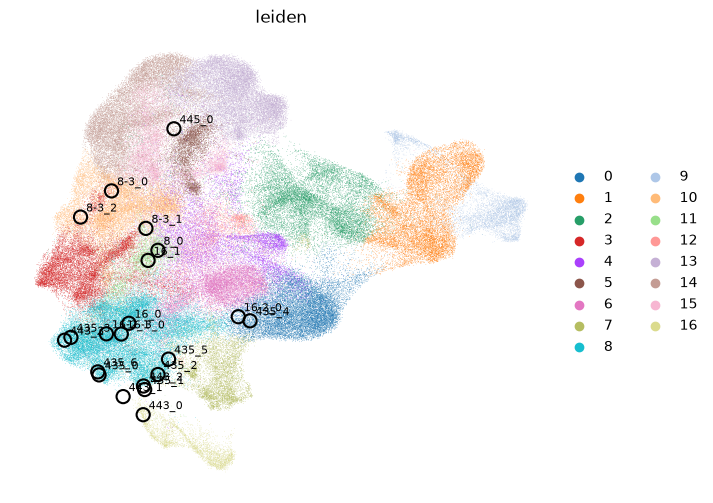

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

sc.pl.umap(
    adata_combined,
    color="leiden",
    frameon=False,
    ax=ax,
    show=False
)

xy = adata_madm_all_query.obsm["X_umap"]

ax.scatter(
    xy[:, 0],
    xy[:, 1],
    s=90,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=10
)

for i, cell in enumerate(adata_madm_all_query.obs["target_cell"]):
    ax.annotate(
        cell,
        xy[i],
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.show()

In [10]:
### NEURONS
### Scale the MADM cells using the same std as in the Xenium neurons so that the MADM cells enter on the same numerical scale
# Same genes, in exactly the same order as the reference
adata_madm_query = adata_madm_neurons[:,adata_neurons_SCNeuron_genes.var_names].copy()
X_query = adata_madm_query.layers["lognorm"].copy()

if sparse.issparse(X_query):
    X_query = X_query.toarray()

# Standard deviations learned from the Xenium neuron reference
ref_std = (
    adata_neurons_SCNeuron_genes
    .var["std"]
    .to_numpy()
    .copy()
)

# Avoid division by zero
ref_std[ref_std == 0] = 1

# Reference was scaled with zero_center=False
X_query = X_query / ref_std

# Reference was clipped at max_value=10
X_query = np.clip(X_query, None, 10)

adata_madm_query.X = X_query.astype(np.float32)

In [11]:
### NEURONS 
### Map the MADM cells onto the Xenium clusters
sc.tl.ingest(adata_madm_query,adata_neurons_SCNeuron_genes,obs="cell_type")

adata_madm_query.obs[
    ["clone", "target_cell", "raw_total_counts", "cell_type"]
]

running ingest


/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


    finished (0:00:11)


,clone,target_cell,raw_total_counts,cell_type
obs_name,,,,
102760_clone1_16_0_102760 clone 1,102760 clone 1,16_0,343,dI6
102760_clone1_16_1_102760 clone 1,102760 clone 1,16_1,418,dI6
102760_clone1_16-2_1_102760 clone 1,102760 clone 1,16-2_1,661,dI6
102760_clone1_16-3_0_102760 clone 1,102760 clone 1,16-3_0,667,dI6
102261 clone1_435_0_102261 clone 1,102261 clone 1,435_0,1037,V2b
102261 clone1_435_1_102261 clone 1,102261 clone 1,435_1,1015,V2a
102261 clone1_435_2_102261 clone 1,102261 clone 1,435_2,698,V2a
102261 clone1_435_3_102261 clone 1,102261 clone 1,435_3,423,V1
102261 clone1_435_4_102261 clone 1,102261 clone 1,435_4,226,dI5-2


In [12]:
from sklearn.neighbors import NearestNeighbors

# Reference Xenium neurons
X_ref = adata_neurons_SCNeuron_genes.obsm["X_pca"]

# MADM cells after ingest
X_madm = adata_madm_query.obsm["X_pca"]

nn = NearestNeighbors(
    n_neighbors=20,
    metric="euclidean"
)

nn.fit(X_ref)

distances, indices = nn.kneighbors(X_madm)

for i, cell_id in enumerate(adata_madm_query.obs["target_cell"]):

    neighbor_types = (
        adata_neurons_SCNeuron_genes
        .obs.iloc[indices[i]]["cell_type"]
    )

    print(f"\n{cell_id}")
    print("Assigned:", adata_madm_query.obs.iloc[i]["cell_type"])
    print(neighbor_types.value_counts())


16_0
Assigned: dI6
cell_type
dI6      20
dI2       0
dI3       0
dI4-1     0
dI4-2     0
dI4-3     0
dI4-4     0
dI4-5     0
dI1       0
dI4-6     0
dI4-7     0
dI5-1     0
dI4-8     0
dI5-3     0
dI5-4     0
dI5-5     0
dI5-2     0
dI5-6     0
V0-1      0
V0-2      0
V1        0
V2a       0
V2b       0
MN        0
V3        0
Name: count, dtype: int64

16_1
Assigned: dI6
cell_type
dI6      20
dI2       0
dI3       0
dI4-1     0
dI4-2     0
dI4-3     0
dI4-4     0
dI4-5     0
dI1       0
dI4-6     0
dI4-7     0
dI5-1     0
dI4-8     0
dI5-3     0
dI5-4     0
dI5-5     0
dI5-2     0
dI5-6     0
V0-1      0
V0-2      0
V1        0
V2a       0
V2b       0
MN        0
V3        0
Name: count, dtype: int64

16-2_1
Assigned: dI6
cell_type
dI6      20
dI2       0
dI3       0
dI4-1     0
dI4-2     0
dI4-3     0
dI4-4     0
dI4-5     0
dI1       0
dI4-6     0
dI4-7     0
dI5-1     0
dI4-8     0
dI5-3     0
dI5-4     0
dI5-5     0
dI5-2     0
dI5-6     0
V0-1      0
V0-2      0
V1        0
V2a 

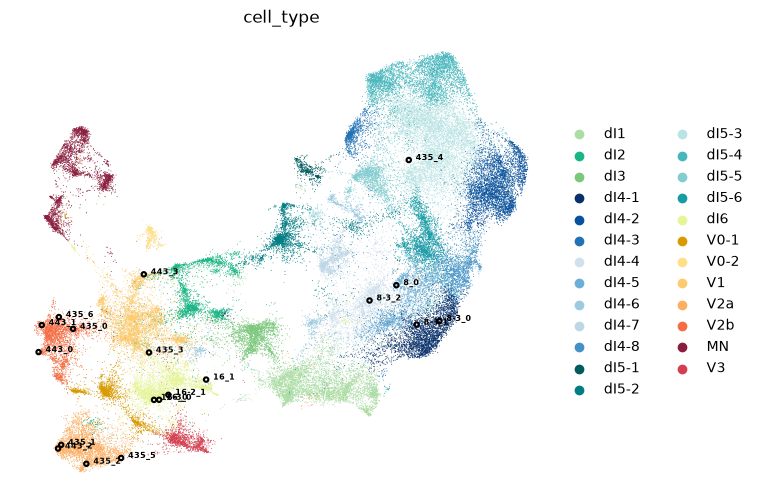

In [13]:
### NEURONS 
### UMAP with mapped MADM cells

fig, ax = plt.subplots(figsize=(7, 6))

sc.pl.umap(
    adata_neurons_SCNeuron_genes,
    color="cell_type",
    frameon=False,
    ax=ax,
    show=False
)

madm_umap = adata_madm_query.obsm["X_umap"]

for i in range(adata_madm_query.n_obs):

    x, y = madm_umap[i]

    ax.scatter(
        x,
        y,
        s=10,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        zorder=10
    )

    ax.annotate(
        adata_madm_query.obs.iloc[i]["target_cell"],
        (x, y),
        xytext=(5, 0),
        textcoords="offset points",
        fontsize=6,
        fontweight="bold",
        zorder=11
    )

plt.show()

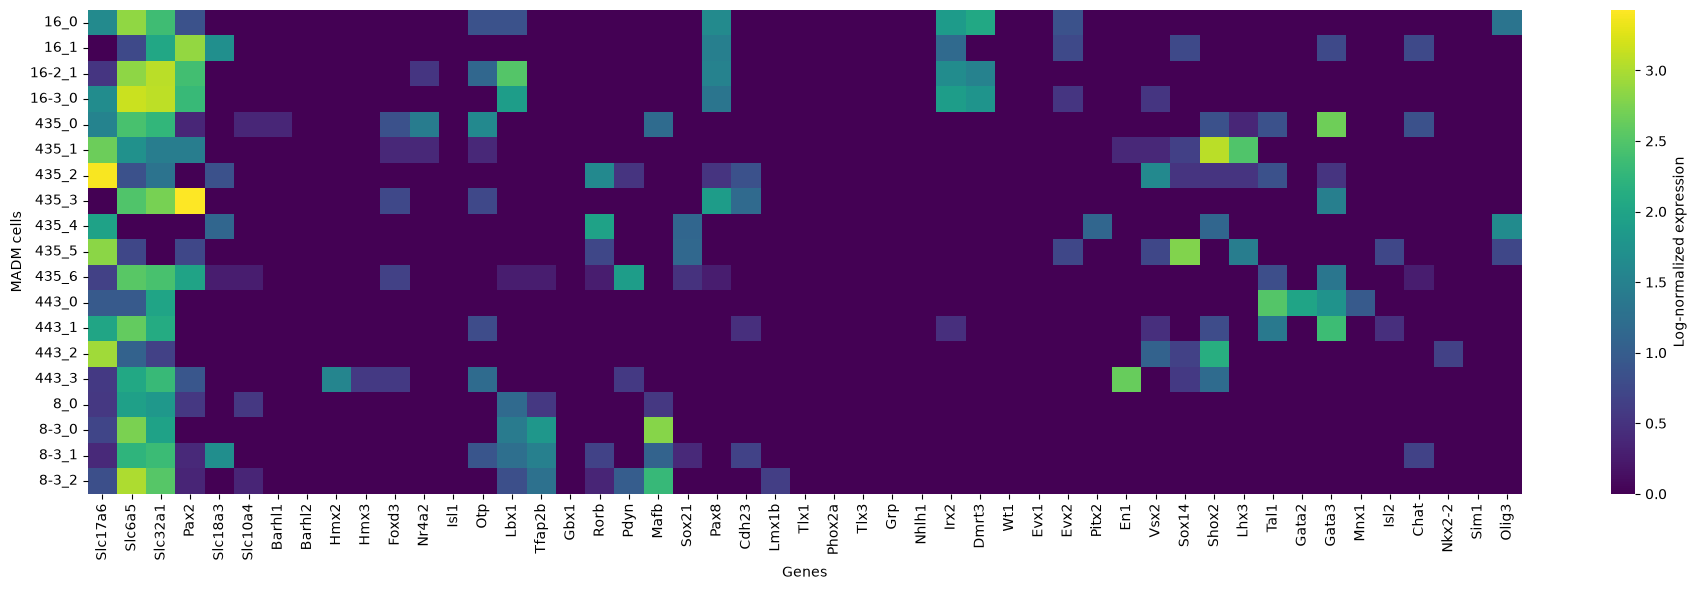

In [15]:
### Heatmap of MADM cell gene expression

import seaborn as sns

# Same genes and same order as the cluster dotplot
genes = xenium_config.select_genes

# MADM log-normalized expression
X = adata_madm_query[:, genes].layers["lognorm"]

if sparse.issparse(X):
    X = X.toarray()

madm_heatmap_df = pd.DataFrame(
    X.T,
    index=genes,
    columns=adata_madm_query.obs["target_cell"]
)

madm_heatmap_df = madm_heatmap_df.loc[xenium_config.select_genes]

madm_heatmap_df = madm_heatmap_df.T

plt.figure(figsize=(19, 6))

sns.heatmap(
    madm_heatmap_df,
    cmap="viridis",
    cbar_kws={"label": "Log-normalized expression"}
)

plt.xlabel("Genes")
plt.ylabel("MADM cells")

plt.tight_layout()
plt.show()

In [16]:
adata_madm_query.write_h5ad("Processed/MADM_mapped_neurons.h5ad")
adata_madm_all_query.write_h5ad("Processed/MADM_mapped_all.h5ad")

In [18]:
### Save another .h5ad file with the mapped MADM cells and all the genes

# Start from the MADM dataset before gene subsetting
adata_madm_all_genes = adata_madm_neurons.copy()

# Keep exactly the same cells and order as the mapped MADM cells
adata_madm_all_genes = adata_madm_all_genes[
    adata_madm_query.obs_names, :
].copy()

# Same genes as in adata_combined
genes = [
    g for g in adata_combined.var_names
    if g in adata_madm_all_genes.var_names
]

adata_madm_all_genes = adata_madm_all_genes[:, genes].copy()

# Transfer mapped cell classifications
for col in ["cell_type", "leiden"]:
    if col in adata_madm_query.obs.columns:
        adata_madm_all_genes.obs[col] = (
            adata_madm_query.obs[col].copy()
        )

# Transfer UMAP coordinates
adata_madm_all_genes.obsm["X_umap"] = (
    adata_madm_query.obsm["X_umap"].copy()
)

# Transfer PCA coordinates if available
if "X_pca" in adata_madm_query.obsm:
    adata_madm_all_genes.obsm["X_pca"] = (
        adata_madm_query.obsm["X_pca"].copy()
    )

adata_madm_all_genes.write_h5ad("Processed/MADM_mapped_neurons_all_genes.h5ad")